### Seismic SPH and Ice-Water Collisions

#### Smoothed Particle Hydrodynamical Simulation

Run simulation for the experimental benchmark (test case resolution)

In [1]:
import hyglac as ss
import numpy as np
import pandas as pd
import time, os

import matplotlib.colors as colors
from matplotlib import pyplot as plt
from matplotlib import cm, rc
from matplotlib.ticker import FormatStrFormatter, NullFormatter, LogLocator
from matplotlib.colors import BoundaryNorm
from scipy.signal import welch

Set up geometry of tank and initial conditions for fluid.  

In [2]:
# set name of simulation
filename = 'scurve_testcase'

# set dimensions of simulation tank
x = 3.0 # length in metres
y = 0.2 # width in metres
z = 1.0 # height in metres
t = 1.5 # duration in seconds
dt_out = 0.005 # duration in seconds

# resolution of simulation
dx = 1/40.
dt = 5e-5

# define functions to set locations of fluid (initially) and obstacle particles
def set_fluid(x, y, z, tol):
    xtol, ytol, ztol = tol, tol, 0.01*tol
    # set region for fluid particles
    return np.where((0.0 + xtol < x) & (x <= 1.0 + xtol) & (-0.1 + ytol < y) & (y < 0.1 - ytol) \
                    & (0.0 + ztol < z) & (z <= 0.5 + ztol))[0]

def set_obstacle(x, y, z, tol):
    xtol, ytol, ztol = tol, tol, 0.01*tol
    # set region for obstacle particles
    return np.where((x <= 0.0 + xtol) | (0.1 - ytol <= y) | (y <= -0.1 + ytol) \
                    | (x >= 3.0 + xtol) | (z <= 0.0 + ztol))[0]

Run smoothed particle hydrodynamical simulation.

In [3]:
ss.run_seismic_sph(x, y, z, t, dx, dt, set_fluid, set_obstacle, output_times=np.arange(0, t + dt_out/2, dt_out), \
                   filename='{}'.format(filename))

3D dam break with 32487 fluid, 24026 boundary, 42120 obstacle particles
3D simulation with 5600 fluid, 24026 boundary, 9633 obstacle particles
Generating output in /Users/rjturner/Documents/Research-Seismology/SeismicGlacier(Paper13)/github/scurve_testcase_output
Precompiled code from: /Users/rjturner/.pysph/source/py3.9-macosx-11.0-arm64/m_fadc31eb60d06b23350663b0d67ffbce.pyx
No of particles:
----------------------------------------------------------------------
  fluid: 5600
  boundary: 24026
  obstacle: 9633
----------------------------------------------------------------------
Setup took: 0.19922 secs
100%
Run took: 434.53153 secs


Plot output of simulation at given time step.

#### Extraction of focres by dynamic pressure smoothing

Find properties of collisions with tank wall.

In [4]:
ss.seismic_sph_interactions(filename='{}'.format(filename), delta=0.01, dx=0.05, dy=0.05, dz=0.05, xrange=[2,4])

Generate force vectors from collision database.

In [5]:
x0, y0, z0 = 3., 0., 500. # define location of point source; in metres
forces_df = ss.seismic_sph_forces_defaults(x0, y0, z0, filename='{}'.format(filename))
forces_df.to_csv('{}_forces.csv'.format(filename))

#### Propogate waves generated by particle collisions

Set up Earth model for seismic waves. The phase velocity of solid ice is 3591.59408 m/s and 1809.077065 m/s at 100 Hz. The density is 916 kg/m^3.

In [6]:
layers = [(0, 3600, 1800, 916), (500, 6000, 3500, 2700)]
earth_model = ss.earth_model(layers)
print(earth_model)

------------------------------------------------------- z = 0.00 km
  vp = 3.60 km/s   vs = 1.80 km/s   rho = 0.92 g/cm^3
------------------------------------------------------- z = 0.50 km
  vp = 6.00 km/s   vs = 3.50 km/s   rho = 2.70 g/cm^3



Generate synthetic seismic signals at a given location.

In [7]:
x, y, z = 0, 1000, 0.5 # define location of seismometer; in metres
t0 = time.time()
seismogram_df = ss.seismic_signals(x, y, z, filename='{}_forces'.format(filename), duration=5.001, \
                                        sampling_rate=100., earth_model=earth_model)
os.makedirs('seismograms', exist_ok=True)
seismogram_df.to_csv('seismograms/{}_seismogram_{:.0f}_{:.0f}_{:.0f}.csv'.format(filename, x, y, z))
print(time.time() - t0)

21.751437187194824


In [8]:
x, y, z = 1000, 0, 0.5 # define location of seismometer; in metres
t0 = time.time()
seismogram_df = ss.seismic_signals(x, y, z, filename='{}_forces'.format(filename), duration=5.001, \
                                        sampling_rate=100., earth_model=earth_model)
seismogram_df.to_csv('seismograms/{}_seismogram_{:.0f}_{:.0f}_{:.0f}.csv'.format(filename, x, y, z))
print(time.time() - t0)

22.451494932174683


In [9]:
x, y, z = 0, 500, 0.5 # define location of seismometer; in metres
t0 = time.time()
seismogram_df = ss.seismic_signals(x, y, z, filename='{}_forces'.format(filename), duration=5.001, \
                                        sampling_rate=100., earth_model=earth_model)
seismogram_df.to_csv('seismograms/{}_seismogram_{:.0f}_{:.0f}_{:.0f}.csv'.format(filename, x, y, z))
print(time.time() - t0)

22.494592905044556


In [10]:
x, y, z = 500, 0, 0.5 # define location of seismometer; in metres
t0 = time.time()
seismogram_df = ss.seismic_signals(x, y, z, filename='{}_forces'.format(filename), duration=5.001, \
                                        sampling_rate=100., earth_model=earth_model)
seismogram_df.to_csv('seismograms/{}_seismogram_{:.0f}_{:.0f}_{:.0f}.csv'.format(filename, x, y, z))
print(time.time() - t0)

22.106011152267456


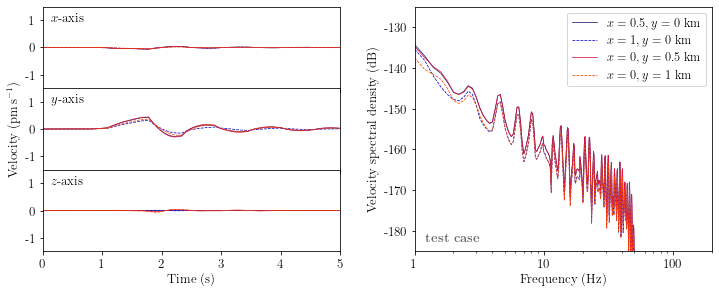

In [12]:
# create plot of seismic signal
fig = plt.figure(figsize=(12, 4.5))
gs = fig.add_gridspec(3, 2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex = ax1, sharey = ax1)
ax3 = fig.add_subplot(gs[2, 0], sharex = ax1, sharey = ax1)
ax4 = fig.add_subplot(gs[:, 1])
axs = [ax1, ax2, ax3, ax4]

fig.subplots_adjust(hspace=0, wspace=0.25)

rc('text', usetex=True)
rc('font', size=13)
rc('legend', fontsize=12.5)
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})

clines = ['midnightblue', 'mediumblue', 'crimson', 'orangered']
slines = ['solid', 'dashed', 'solid', 'dashed']
labels = []

for i in range(0, 4):
    if i == 0:
        x, y, z = 500, 0, 0.5 # define location of seismometer; in metres
    elif i == 1:
        x, y, z = 1000, 0, 0.5 # define location of seismometer; in metres
    elif i == 2:
        x, y, z = 0, 500, 0.5 # define location of seismometer; in metres
    else:
        x, y, z = 0, 1000, 0.5 # define location of seismometer; in metres
    labels.append(r'$x = {:g}, y = {:g}$~km'.format(x/1000, y/1000))
        
    seismogram_df = pd.read_csv('seismograms/{}_seismogram_{:.0f}_{:.0f}_{:.0f}.csv'.format(filename, x, y, z))
    
    x_detrended, y_detrended, z_detrended = seismogram_df['vel_1'].values, seismogram_df['vel_2'].values, seismogram_df['vel_3'].values
        
    axs[0].plot(seismogram_df['t'].values, x_detrended*1e12, c=clines[i], ls=slines[i], linewidth=0.75)
    axs[1].plot(seismogram_df['t'].values, y_detrended*1e12, c=clines[i], ls=slines[i], linewidth=0.75)
    axs[2].plot(seismogram_df['t'].values, z_detrended*1e12, c=clines[i], ls=slines[i], linewidth=0.75)

    f, Px = welch(x_detrended, fs=1/(seismogram_df['t'].values[1] - seismogram_df['t'].values[0]), nperseg=500)
    f, Py = welch(x_detrended, fs=1/(seismogram_df['t'].values[1] - seismogram_df['t'].values[0]), nperseg=500)
    f, Pz = welch(x_detrended, fs=1/(seismogram_df['t'].values[1] - seismogram_df['t'].values[0]), nperseg=500)
                  
    axs[3].plot(f, 10*np.log10(np.sqrt(np.sqrt(np.abs(Px)**2 + np.abs(Py)**2 + np.abs(Pz)**2))), \
                c=clines[i], ls=slines[i], linewidth=0.75, label=labels[i])

axs[0].set_xlim([0, seismogram_df['t'].values[-1] + seismogram_df['t'].values[1] - seismogram_df['t'].values[0]])
factor = 1
axs[0].set_ylim([-1.5*factor, 1.5*factor])
axs[0].set_yticks([-factor, 0, factor])
axs[0].yaxis.set_major_formatter(FormatStrFormatter('%g'))
plt.setp(axs[0].get_xticklabels(), visible=False)
plt.setp(axs[1].get_xticklabels(), visible=False)

axs[2].set_xlabel(r'Time (s)')
axs[1].set_ylabel(r'Velocity ($\rm pm\,s^{-1}$)')

axs[0].text(0.15, 0.95*factor, r'$x$-axis')
axs[1].text(0.15, 0.95*factor, r'$y$-axis')
axs[2].text(0.15, 0.95*factor, r'$z$-axis')

axs[3].set_xlim([1, 2e2])
axs[3].set_ylim([-185, -125])
axs[3].set_xscale('log')
axs[3].xaxis.set_major_formatter(FormatStrFormatter('%g'))
axs[3].yaxis.set_major_formatter(FormatStrFormatter('%g'))
axs[3].set_xlabel(r'Frequency (Hz)')
axs[3].set_ylabel(r'Velocity spectral density ($\rm dB$)')

axs[3].legend(loc='upper right')
axs[3].text(1.2, -182.5, r'\textbf{test case}', color='dimgrey', ha='left', bbox=dict(boxstyle='round', \
                facecolor='white', edgecolor='white', pad=0.15))

plt.savefig('waveform_testcase.eps', format='eps', dpi=300)

plt.show()